<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/12-ml-network-intrusion-detection/ml_based_network_intrusion_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 ML-Based Network Intrusion Detection Using CICIDS2017

**Thesis-core experiment | Binary + Multiclass classification**

This notebook loads the full CICIDS2017 CSV collection and compares four tree-based machine-learning models:

- Random Forest
- XGBoost
- LightGBM
- CatBoost

Two experiments are performed independently:

1. **Binary classification:** `BENIGN` vs. `ATTACK`
2. **Multiclass classification:** `BENIGN` and each observed attack category

The notebook includes data auditing, cleaning, duplicate removal, leakage-aware feature exclusion, stratified train/test splitting, evaluation, error analysis, feature importance, model export, and reproducibility metadata.

> **Research caution:** A stratified random split is a useful baseline, but flows from the same capture period may share characteristics across train and test. Do not describe it as a fully independent temporal or cross-dataset evaluation. A later thesis experiment should add a carefully designed time-/capture-aware or cross-dataset test.

## 1. Dataset preparation

Download the **CICIDS2017 machine-learning CSV files** from the official Canadian Institute for Cybersecurity dataset page:

https://www.unb.ca/cic/datasets/ids-2017.html

Extract the CSV files into one Google Drive folder, for example:

`MyDrive/CICIDS2017/`

Use one consistent CSV collection. Do not place multiple copies or alternative processed versions of the same dataset inside the folder. The loader searches recursively for `.csv` files.

The notebook does not download from an unofficial Kaggle mirror automatically, because dataset mirrors and their contents can differ.

### Cell 2 -  Install required libraries

In [ ]:
!pip -q install xgboost lightgbm catboost joblib

### Cell 3 -  Imports, reproducibility, and runtime check

In [ ]:
import os
import re
import gc
import json
import time
import glob
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import joblib

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
except Exception:
    print("PyTorch not required for this project.")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Notebook runtime initialized.")

PyTorch: 2.14.1+cpu
CUDA available: False
NumPy: 2.1.3
Pandas: 2.2.3
Notebook runtime initialized.


###Cell 4 -  Mount Google Drive and configure paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Change this path if your CICIDS2017 CSV folder has a different name.
DATA_DIR = Path('/content/drive/MyDrive/Colab Notebooks/Projects House/Project-12/CICIDS2017')
OUTPUT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/Projects House/Project-12/Project12_Outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder exists:", DATA_DIR.exists())
print("Output folder:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder exists: True
Output folder: /content/drive/MyDrive/Colab Notebooks/Projects House/Project-12/Project12_Outputs


### Cell 5 -  Find all dataset CSV files

In [ ]:
csv_files = sorted(DATA_DIR.rglob("*.csv")) if DATA_DIR.exists() else []
print("CSV files found:", len(csv_files))
for p in csv_files:
    print(p.name, f"({p.stat().st_size / (1024**2):.1f} MB)")

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {DATA_DIR}. Extract the CICIDS2017 CSV files into this folder."
    )

CSV files found: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (73.6 MB)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (73.3 MB)
Friday-WorkingHours-Morning.pcap_ISCX.csv (55.6 MB)
Monday-WorkingHours.pcap_ISCX.csv (168.7 MB)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (79.3 MB)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (49.6 MB)
Tuesday-WorkingHours.pcap_ISCX.csv (128.8 MB)
Wednesday-workingHours.pcap_ISCX.csv (214.7 MB)


### Cell 6 -  Load and combine the full CSV collection

In [ ]:
# CICIDS2017 CSVs can be large. This cell loads one file at a time and then combines them.
# If your Colab runtime runs out of RAM, use a High-RAM runtime or process files in batches.

frames = []
file_load_log = []

for file_path in csv_files:
    print("Loading:", file_path.name)
    try:
        part = pd.read_csv(file_path, low_memory=False, encoding="utf-8")
    except UnicodeDecodeError:
        part = pd.read_csv(file_path, low_memory=False, encoding="latin1")

    part.columns = [str(c).replace("\ufeff", "").strip() for c in part.columns]
    part["__source_file"] = file_path.name
    file_load_log.append({
        "file": file_path.name,
        "rows": int(len(part)),
        "columns": int(part.shape[1])
    })
    frames.append(part)
    del part
    gc.collect()

df = pd.concat(frames, ignore_index=True, sort=False)
del frames
gc.collect()

pd.DataFrame(file_load_log).to_csv(OUTPUT_DIR / "source_file_audit.csv", index=False)

print("Combined shape:", df.shape)
display(df.head())

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Combined shape: (2830743, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,__source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


### Cell 7 -  Inspect columns and identify the target label

In [ ]:
# Normalize column whitespace and locate the label column.
df.columns = [str(c).strip() for c in df.columns]
label_candidates = [c for c in df.columns if c.strip().lower() == "label"]

if not label_candidates:
    raise ValueError(
        "Could not find a Label column. Inspect df.columns and verify that the correct CICIDS2017 CSV files were loaded."
    )

LABEL_COL = label_candidates[0]
print("Target column:", LABEL_COL)
print("Number of combined rows:", len(df))
print("Number of columns:", len(df.columns))
print("Null values in target:", int(df[LABEL_COL].isna().sum()))
display(df[LABEL_COL].value_counts(dropna=False).to_frame("count"))

Target column: Label
Number of combined rows: 2830743
Number of columns: 80
Null values in target: 0


,count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


### Cell 8 -  Basic data cleaning and label normalization

In [ ]:
# Remove rows without a target label.
df = df.dropna(subset=[LABEL_COL]).copy()

# Normalize labels by trimming leading/trailing spaces.
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
df = df[df[LABEL_COL].ne("")].copy()

# Convert common textual infinity representations and numeric columns safely.
# The source-file column is retained only for auditing and is not used as a model feature.
df.replace([np.inf, -np.inf, "Infinity", "-Infinity", "inf", "-inf"], np.nan, inplace=True)

# Remove rows that are exact duplicates across the combined raw dataset.
before_dedup = len(df)
dedup_columns = [c for c in df.columns if c != "__source_file"]
df = df.drop_duplicates(subset=dedup_columns).reset_index(drop=True)
duplicates_removed = before_dedup - len(df)

print("Exact duplicate rows removed:", duplicates_removed)
print("Shape after label cleaning and deduplication:", df.shape)

Exact duplicate rows removed: 308381
Shape after label cleaning and deduplication: (2522362, 80)


### Cell 9 -  Explore class distribution

,label,samples,percentage
0,BENIGN,2096484,83.115905
1,DoS Hulk,172849,6.852664
2,DDoS,128016,5.075243
3,PortScan,90819,3.600554
4,DoS GoldenEye,10286,0.407792
5,FTP-Patator,5933,0.235216
6,DoS slowloris,5385,0.213490
7,DoS Slowhttptest,5228,0.207266
8,SSH-Patator,3219,0.127618
9,Bot,1953,0.077427


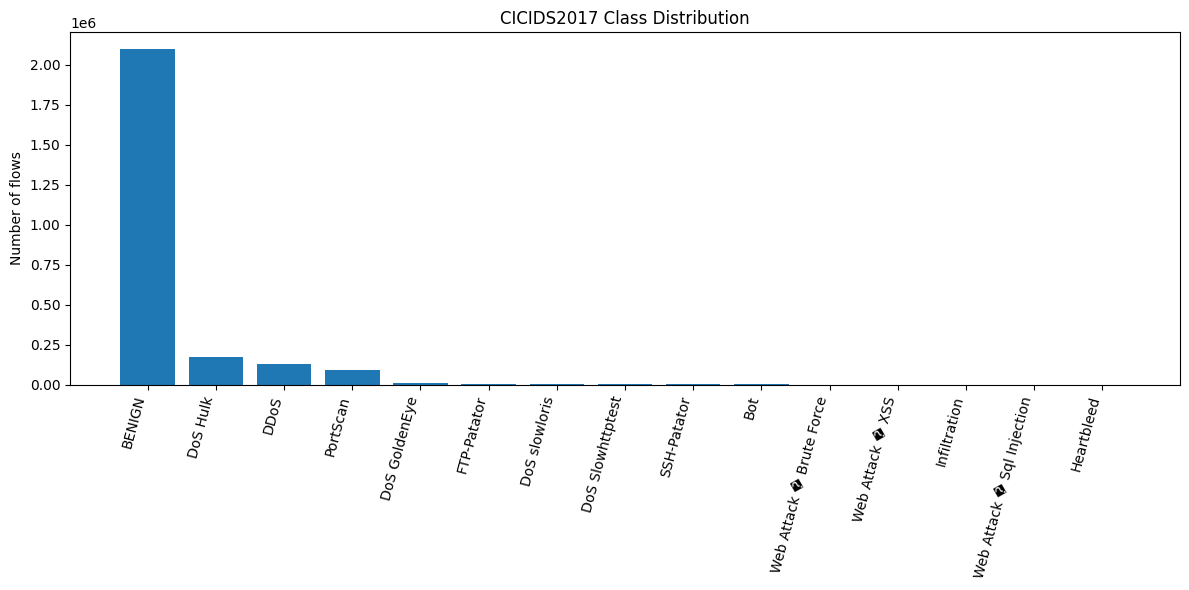

In [ ]:
label_counts = df[LABEL_COL].value_counts().sort_values(ascending=False)
label_distribution = label_counts.rename_axis("label").reset_index(name="samples")
label_distribution["percentage"] = 100 * label_distribution["samples"] / label_distribution["samples"].sum()
display(label_distribution)

plt.figure(figsize=(12, 6))
plt.bar(label_distribution["label"], label_distribution["samples"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of flows")
plt.title("CICIDS2017 Class Distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160)
plt.show()

label_distribution.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)

### Cell 10 -  Select numeric features and exclude identifier/leakage-prone columns

In [ ]:
# Drop identifiers and metadata that can let a model memorize hosts or timestamps.
# Keep numeric traffic features such as Destination Port and Protocol when present.
DROP_COLUMNS_EXACT = {
    LABEL_COL,
    "__source_file",
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
}

drop_cols = [c for c in df.columns if c in DROP_COLUMNS_EXACT]
X_raw = df.drop(columns=drop_cols, errors="ignore").copy()

# Convert all candidate features to numeric; non-numeric values become NaN.
for col in X_raw.columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors="coerce")

# Remove columns that are entirely missing or constant.
all_missing_cols = X_raw.columns[X_raw.isna().all()].tolist()
X_raw.drop(columns=all_missing_cols, inplace=True)

constant_cols = [c for c in X_raw.columns if X_raw[c].nunique(dropna=True) <= 1]
X_raw.drop(columns=constant_cols, inplace=True)

# Replace infinities after numeric conversion.
X_raw.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Dropped identifier/metadata columns:", drop_cols)
print("Dropped all-missing columns:", all_missing_cols)
print("Dropped constant columns:", constant_cols)
print("Feature matrix shape:", X_raw.shape)

if X_raw.shape[1] == 0:
    raise ValueError("No usable numeric features remain after preprocessing.")

Dropped identifier/metadata columns: ['Label', '__source_file']
Dropped all-missing columns: []
Dropped constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Feature matrix shape: (2522362, 70)


### Cell 11 -  Build binary and multiclass targets

In [ ]:
# Binary target: BENIGN = 0; every other observed label = 1 (ATTACK).
labels_original = df[LABEL_COL].astype(str).str.strip()
is_benign = labels_original.str.upper().eq("BENIGN")

y_binary = pd.Series(np.where(is_benign, "BENIGN", "ATTACK"), index=df.index, name="binary_label")
y_multiclass = labels_original.rename("multiclass_label")

print("Binary distribution:")
display(y_binary.value_counts().to_frame("samples"))

print("Multiclass distribution:")
display(y_multiclass.value_counts().to_frame("samples"))

Binary distribution:


,samples
binary_label,
BENIGN,2096484
ATTACK,425878


Multiclass distribution:


,samples
multiclass_label,
BENIGN,2096484
DoS Hulk,172849
DDoS,128016
PortScan,90819
DoS GoldenEye,10286
FTP-Patator,5933
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219


### Cell 12 -  Configure experiments and model training

In [ ]:
# None means train on all eligible rows. For a preliminary runtime test only,
# you may set a number such as 300_000; report that experiment as sampled, not full-data.
MAX_TRAINING_ROWS = None

TEST_SIZE = 0.20
N_JOBS = -1

MODEL_CONFIG = {
    "Random Forest": {
        "n_estimators": 200,
        "random_state": SEED,
        "n_jobs": N_JOBS,
        "class_weight": None,
        "max_features": "sqrt"
    },
    "XGBoost": {
        "n_estimators": 250,
        "max_depth": 8,
        "learning_rate": 0.08,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "tree_method": "hist",
        "eval_metric": "mlogloss",
        "random_state": SEED,
        "n_jobs": N_JOBS
    },
    "LightGBM": {
        "n_estimators": 250,
        "learning_rate": 0.08,
        "num_leaves": 31,
        "random_state": SEED,
        "n_jobs": N_JOBS,
        "verbosity": -1
    },
    "CatBoost": {
        "iterations": 250,
        "depth": 8,
        "learning_rate": 0.08,
        "loss_function": "MultiClass",
        "verbose": False,
        "random_seed": SEED,
        "thread_count": N_JOBS
    }
}

print("Maximum training rows:", MAX_TRAINING_ROWS)
print("Test size:", TEST_SIZE)

Maximum training rows: None
Test size: 0.2


### Cell 13 -  Define model factory and evaluation utilities

In [ ]:
def make_model(model_name, n_classes):
    cfg = MODEL_CONFIG[model_name].copy()

    if model_name == "Random Forest":
        return RandomForestClassifier(**cfg)

    if model_name == "XGBoost":
        if n_classes == 2:
            cfg["objective"] = "binary:logistic"
            cfg["eval_metric"] = "logloss"
        else:
            cfg["objective"] = "multi:softprob"
            cfg["num_class"] = n_classes
        return XGBClassifier(**cfg)

    if model_name == "LightGBM":
        cfg["objective"] = "binary" if n_classes == 2 else "multiclass"
        if n_classes > 2:
            cfg["num_class"] = n_classes
        return LGBMClassifier(**cfg)

    if model_name == "CatBoost":
        cfg["loss_function"] = "Logloss" if n_classes == 2 else "MultiClass"
        return CatBoostClassifier(**cfg)

    raise ValueError(f"Unknown model: {model_name}")


def macro_fpr_from_confusion_matrix(cm):
    # One-vs-rest FPR for each class, macro-averaged.
    total = cm.sum()
    fprs = []
    for i in range(cm.shape[0]):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        denom = fp + tn
        fprs.append(fp / denom if denom else 0.0)
    return float(np.mean(fprs))


def evaluate_predictions(y_true, y_pred, label_names):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(label_names)))
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "fpr_macro_ovr": macro_fpr_from_confusion_matrix(cm),
        "confusion_matrix": cm
    }

Cell 14 -  Define a reusable experiment runner

In [ ]:
def run_experiment(experiment_name, X, y_text):
    print("\n" + "=" * 80)
    print("EXPERIMENT:", experiment_name)
    print("=" * 80)

    valid = y_text.notna()
    X_exp = X.loc[valid].copy()
    y_exp_text = y_text.loc[valid].astype(str)

    # Encode target labels for consistent estimator compatibility.
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(y_exp_text)
    label_names = list(encoder.classes_)

    # Every class must have at least two rows for a stratified holdout.
    counts = pd.Series(y_encoded).value_counts()
    rare = [label_names[int(i)] for i, count in counts.items() if count < 2]
    if rare:
        raise ValueError(f"Classes with fewer than 2 samples cannot be stratified: {rare}")

    # Optional stratified sample for a runtime pilot. Default is the full dataset.
    if MAX_TRAINING_ROWS is not None and len(X_exp) > MAX_TRAINING_ROWS:
        X_exp, _, y_encoded, _ = train_test_split(
            X_exp, y_encoded,
            train_size=MAX_TRAINING_ROWS,
            random_state=SEED,
            stratify=y_encoded
        )

    X_train, X_test, y_train, y_test = train_test_split(
        X_exp, y_encoded,
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=y_encoded
    )

    print("Rows used:", len(X_exp))
    print("Train rows:", len(X_train), "| Test rows:", len(X_test))
    print("Number of classes:", len(label_names))
    print("Features:", X_train.shape[1])

    # Median imputation is fitted on training data only, preventing test-set leakage.
    results = []
    fitted_models = {}
    reports = {}
    confusion_matrices = {}
    importance_frames = []

    sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

    for model_name in MODEL_CONFIG:
        print(f"\nTraining {model_name}...")
        model = make_model(model_name, len(label_names))

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", model)
        ])

        start = time.time()
        fit_kwargs = {"model__sample_weight": sample_weights}

        pipeline.fit(X_train, y_train, **fit_kwargs)
        train_seconds = time.time() - start

        pred_start = time.time()
        y_pred = pipeline.predict(X_test)
        inference_seconds = time.time() - pred_start

        metrics = evaluate_predictions(y_test, y_pred, label_names)
        row = {
            "experiment": experiment_name,
            "model": model_name,
            "train_samples": len(X_train),
            "test_samples": len(X_test),
            "n_features": X_train.shape[1],
            "training_time_seconds": train_seconds,
            "inference_time_seconds": inference_seconds,
            "accuracy": metrics["accuracy"],
            "precision_macro": metrics["precision_macro"],
            "recall_macro": metrics["recall_macro"],
            "f1_macro": metrics["f1_macro"],
            "fpr_macro_ovr": metrics["fpr_macro_ovr"]
        }
        results.append(row)
        fitted_models[model_name] = pipeline
        confusion_matrices[model_name] = metrics["confusion_matrix"]

        report = classification_report(
            y_test, y_pred,
            labels=np.arange(len(label_names)),
            target_names=label_names,
            output_dict=True,
            zero_division=0
        )
        reports[model_name] = pd.DataFrame(report).transpose()

        # Tree-based feature importance, where exposed by the fitted estimator.
        estimator = pipeline.named_steps["model"]
        if hasattr(estimator, "feature_importances_"):
            importance_frames.append(pd.DataFrame({
                "experiment": experiment_name,
                "model": model_name,
                "feature": X_train.columns,
                "importance": estimator.feature_importances_
            }).sort_values("importance", ascending=False))

        print(
            f"{model_name}: Accuracy={metrics['accuracy']:.4f}, "
            f"Macro-F1={metrics['f1_macro']:.4f}, "
            f"Macro-FPR={metrics['fpr_macro_ovr']:.4f}, "
            f"Train time={train_seconds:.1f}s"
        )

        del model, pipeline
        gc.collect()

    results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False)
    importance_df = (
        pd.concat(importance_frames, ignore_index=True)
        if importance_frames else pd.DataFrame()
    )

    return {
        "results": results_df,
        "models": fitted_models,
        "reports": reports,
        "confusion_matrices": confusion_matrices,
        "label_names": label_names,
        "label_encoder": encoder,
        "X_test": X_test,
        "y_test": y_test,
        "feature_names": list(X_train.columns),
        "feature_importance": importance_df
    }

### Cell 15 -  Run Experiment A - Binary classification

In [ ]:
binary_results = run_experiment(
    experiment_name="Binary",
    X=X_raw,
    y_text=y_binary
)

display(binary_results["results"])
binary_results["results"].to_csv(OUTPUT_DIR / "binary_model_comparison.csv", index=False)


EXPERIMENT: Binary
Rows used: 2522362
Train rows: 2017889 | Test rows: 504473
Number of classes: 2
Features: 70

Training Random Forest...
Random Forest: Accuracy=0.9986, Macro-F1=0.9975, Macro-FPR=0.0026, Train time=442.1s

Training XGBoost...
XGBoost: Accuracy=0.9990, Macro-F1=0.9983, Macro-FPR=0.0007, Train time=53.4s

Training LightGBM...
LightGBM: Accuracy=0.9990, Macro-F1=0.9982, Macro-FPR=0.0007, Train time=40.2s

Training CatBoost...
CatBoost: Accuracy=0.9989, Macro-F1=0.9980, Macro-FPR=0.0008, Train time=70.7s


,experiment,model,train_samples,test_samples,n_features,training_time_seconds,inference_time_seconds,accuracy,precision_macro,recall_macro,f1_macro,fpr_macro_ovr
1,Binary,XGBoost,2017889,504473,70,53.406903,0.770659,0.999047,0.997344,0.999272,0.998305,0.000728
2,Binary,LightGBM,2017889,504473,70,40.156578,1.792130,0.998989,0.997129,0.999284,0.998203,0.000716
3,Binary,CatBoost,2017889,504473,70,70.682187,0.389917,0.998858,0.996783,0.999168,0.997971,0.000832
0,Binary,Random Forest,2017889,504473,70,442.097942,2.188544,0.998608,0.997683,0.997357,0.997520,0.002643


### Cell 16 - Plot binary model comparison

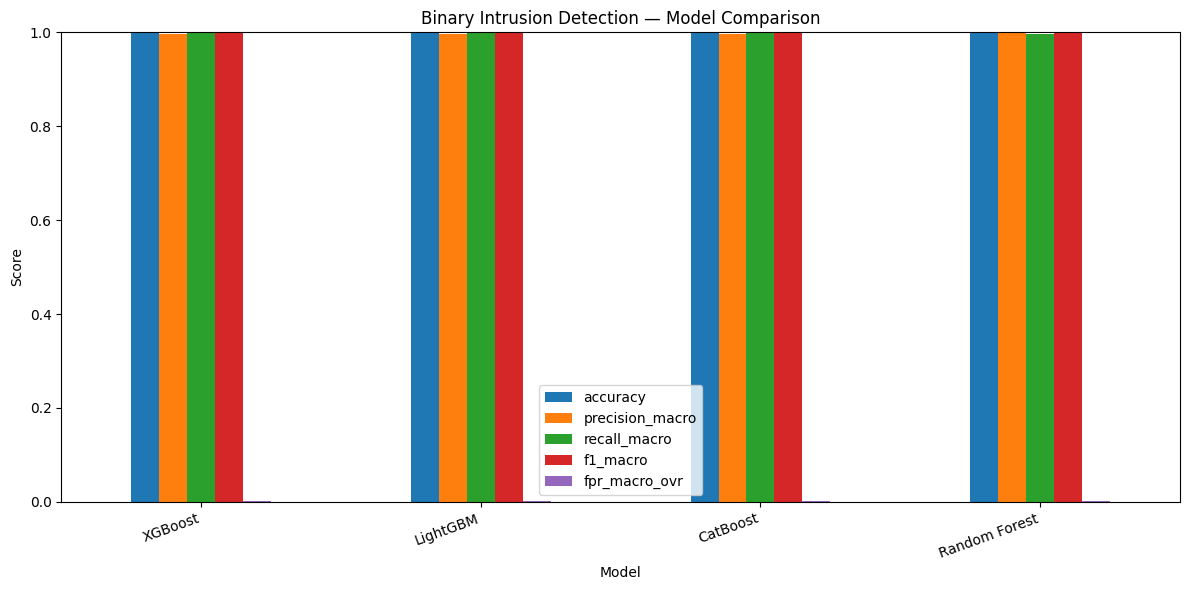

In [ ]:
metrics_to_plot = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "fpr_macro_ovr"]

ax = binary_results["results"].set_index("model")[metrics_to_plot].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
ax.set_title("Binary Intrusion Detection — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "binary_model_comparison.png", dpi=160)
plt.show()

### Cell 17 -  Binary classification reports and confusion matrices


 Random Forest — Binary classification report


,precision,recall,f1-score,support
ATTACK,0.996287,0.995468,0.995877,85176.000000
BENIGN,0.999080,0.999246,0.999163,419297.000000
accuracy,0.998608,0.998608,0.998608,0.998608
macro avg,0.997683,0.997357,0.997520,504473.000000
weighted avg,0.998608,0.998608,0.998608,504473.000000


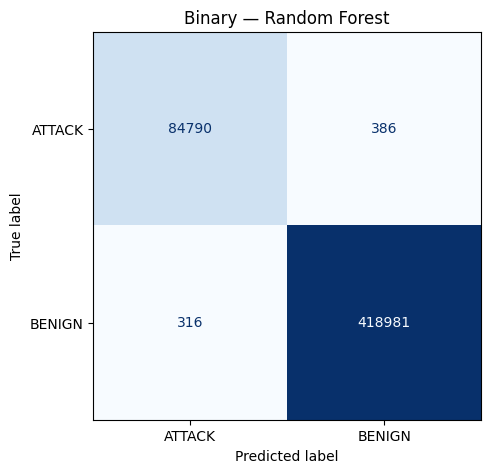


 XGBoost — Binary classification report


,precision,recall,f1-score,support
ATTACK,0.994766,0.999613,0.997183,85176.000000
BENIGN,0.999921,0.998932,0.999426,419297.000000
accuracy,0.999047,0.999047,0.999047,0.999047
macro avg,0.997344,0.999272,0.998305,504473.000000
weighted avg,0.999051,0.999047,0.999047,504473.000000


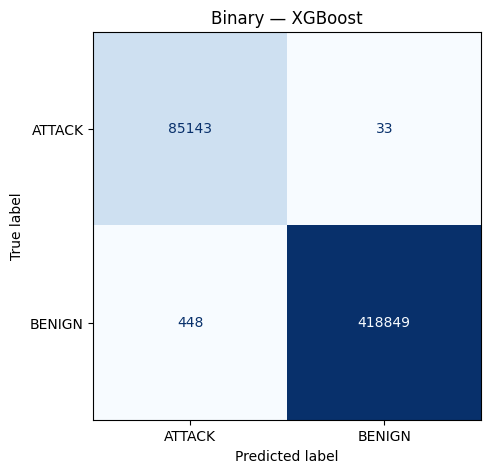


 LightGBM — Binary classification report


,precision,recall,f1-score,support
ATTACK,0.994313,0.999730,0.997014,85176.000000
BENIGN,0.999945,0.998839,0.999392,419297.000000
accuracy,0.998989,0.998989,0.998989,0.998989
macro avg,0.997129,0.999284,0.998203,504473.000000
weighted avg,0.998994,0.998989,0.998990,504473.000000


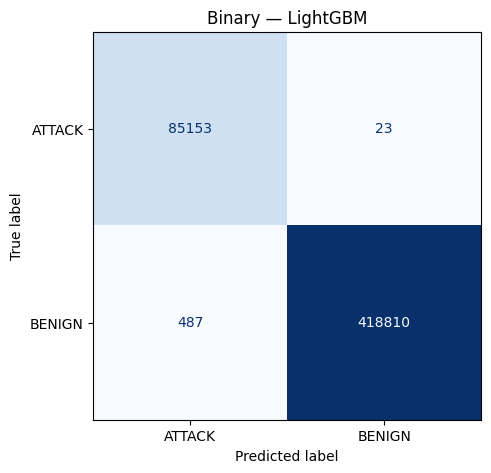


 CatBoost — Binary classification report


,precision,recall,f1-score,support
ATTACK,0.993640,0.999636,0.996629,85176.000000
BENIGN,0.999926,0.998700,0.999313,419297.000000
accuracy,0.998858,0.998858,0.998858,0.998858
macro avg,0.996783,0.999168,0.997971,504473.000000
weighted avg,0.998865,0.998858,0.998860,504473.000000


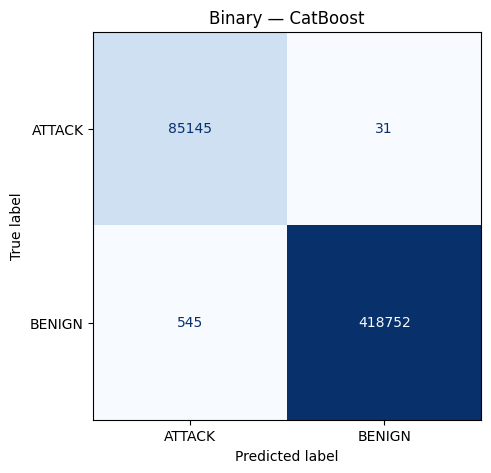

In [ ]:
for model_name, report_df in binary_results["reports"].items():
    print("\n", model_name, "— Binary classification report")
    display(report_df)
    safe_name = re.sub(r"[^a-z0-9]+", "_", model_name.lower()).strip("_")
    report_df.to_csv(OUTPUT_DIR / f"binary_{safe_name}_classification_report.csv")

    cm = binary_results["confusion_matrices"][model_name]
    cm_df = pd.DataFrame(
        cm,
        index=binary_results["label_names"],
        columns=binary_results["label_names"]
    )
    cm_df.to_csv(OUTPUT_DIR / f"binary_{safe_name}_confusion_matrix.csv")

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=binary_results["label_names"]
    )
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Binary — {model_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"binary_{safe_name}_confusion_matrix.png", dpi=160)
    plt.show()

### Cell 18 -  Run Experiment B - Multiclass classification

In [ ]:
multiclass_results = run_experiment(
    experiment_name="Multiclass",
    X=X_raw,
    y_text=y_multiclass
)

display(multiclass_results["results"])
multiclass_results["results"].to_csv(OUTPUT_DIR / "multiclass_model_comparison.csv", index=False)


EXPERIMENT: Multiclass
Rows used: 2522362
Train rows: 2017889 | Test rows: 504473
Number of classes: 15
Features: 70

Training Random Forest...
Random Forest: Accuracy=0.9983, Macro-F1=0.8980, Macro-FPR=0.0004, Train time=431.2s

Training XGBoost...
XGBoost: Accuracy=0.9986, Macro-F1=0.9077, Macro-FPR=0.0001, Train time=420.0s

Training LightGBM...
LightGBM: Accuracy=0.4934, Macro-F1=0.2122, Macro-FPR=0.0368, Train time=231.8s

Training CatBoost...
CatBoost: Accuracy=0.9882, Macro-F1=0.6920, Macro-FPR=0.0008, Train time=1591.2s


,experiment,model,train_samples,test_samples,n_features,training_time_seconds,inference_time_seconds,accuracy,precision_macro,recall_macro,f1_macro,fpr_macro_ovr
1,Multiclass,XGBoost,2017889,504473,70,419.978697,6.776776,0.998585,0.881546,0.947630,0.907701,0.000101
0,Multiclass,Random Forest,2017889,504473,70,431.194921,3.218450,0.998301,0.937910,0.874039,0.898037,0.000379
3,Multiclass,CatBoost,2017889,504473,70,1591.152485,0.598951,0.988206,0.645386,0.940126,0.691978,0.000806
2,Multiclass,LightGBM,2017889,504473,70,231.806777,13.496197,0.493350,0.192712,0.682236,0.212182,0.036794


### Cell 19 -  Plot multiclass model comparison

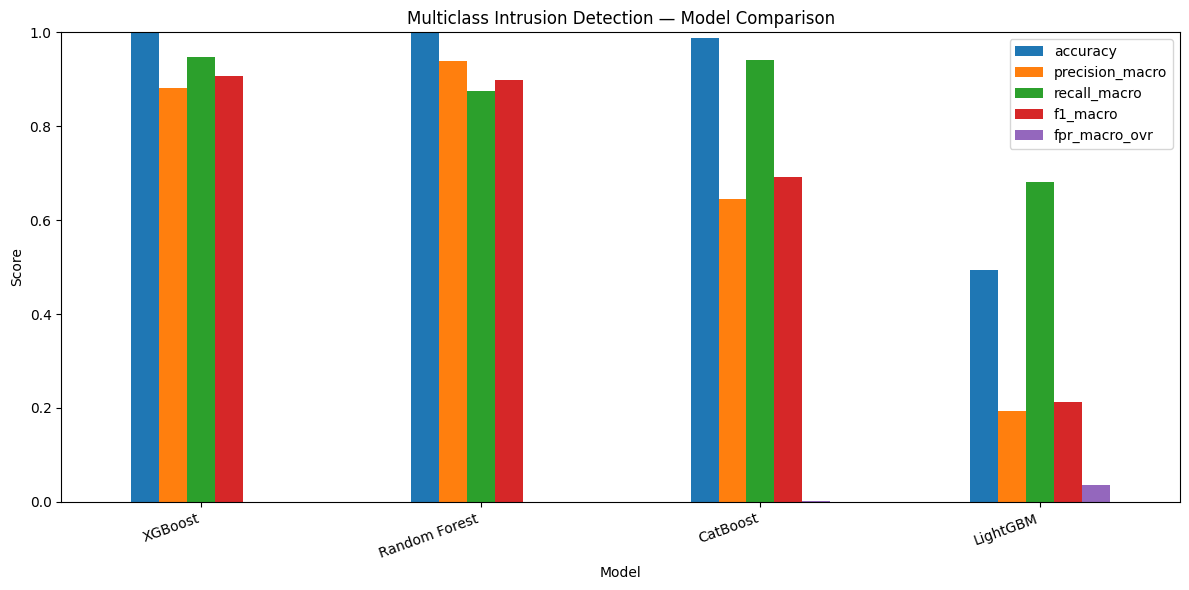

In [ ]:
ax = multiclass_results["results"].set_index("model")[metrics_to_plot].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
ax.set_title("Multiclass Intrusion Detection — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "multiclass_model_comparison.png", dpi=160)
plt.show()

### Cell 20 -  Multiclass classification reports and confusion matrices


 Random Forest — Multiclass classification report


,precision,recall,f1-score,support
BENIGN,0.999032,0.999299,0.999165,419297.000000
Bot,0.895349,0.787724,0.838095,391.000000
DDoS,0.999961,0.999805,0.999883,25603.000000
DoS GoldenEye,0.998532,0.991736,0.995122,2057.000000
DoS Hulk,0.997512,0.997194,0.997353,34570.000000
DoS Slowhttptest,0.987643,0.993308,0.990467,1046.000000
DoS slowloris,0.998136,0.994429,0.996279,1077.000000
FTP-Patator,1.000000,0.997473,0.998735,1187.000000
Heartbleed,1.000000,1.000000,1.000000,2.000000
Infiltration,1.000000,0.714286,0.833333,7.000000


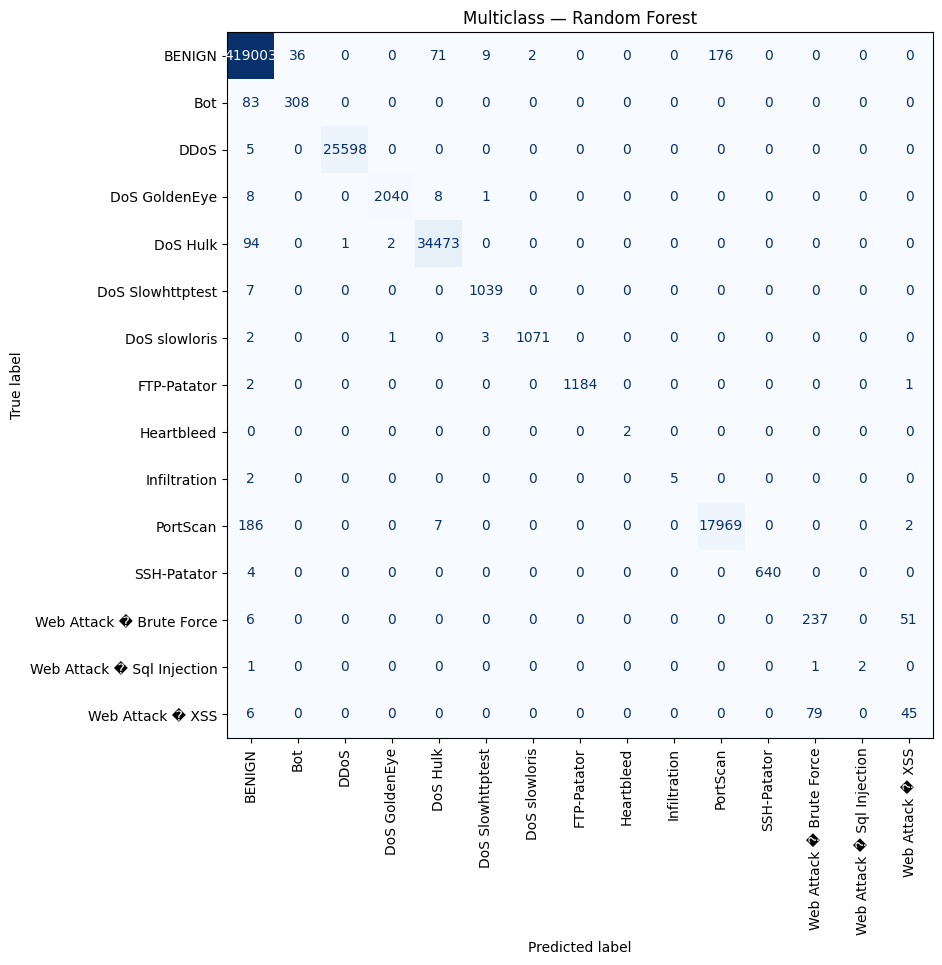


 XGBoost — Multiclass classification report


,precision,recall,f1-score,support
BENIGN,0.999983,0.998772,0.999377,419297.000000
Bot,0.639935,1.000000,0.780439,391.000000
DDoS,0.999532,1.000000,0.999766,25603.000000
DoS GoldenEye,0.984195,0.999028,0.991556,2057.000000
DoS Hulk,0.997833,0.999161,0.998497,34570.000000
DoS Slowhttptest,0.981114,0.993308,0.987173,1046.000000
DoS slowloris,0.994439,0.996286,0.995362,1077.000000
FTP-Patator,0.999158,0.999158,0.999158,1187.000000
Heartbleed,1.000000,1.000000,1.000000,2.000000
Infiltration,0.875000,1.000000,0.933333,7.000000


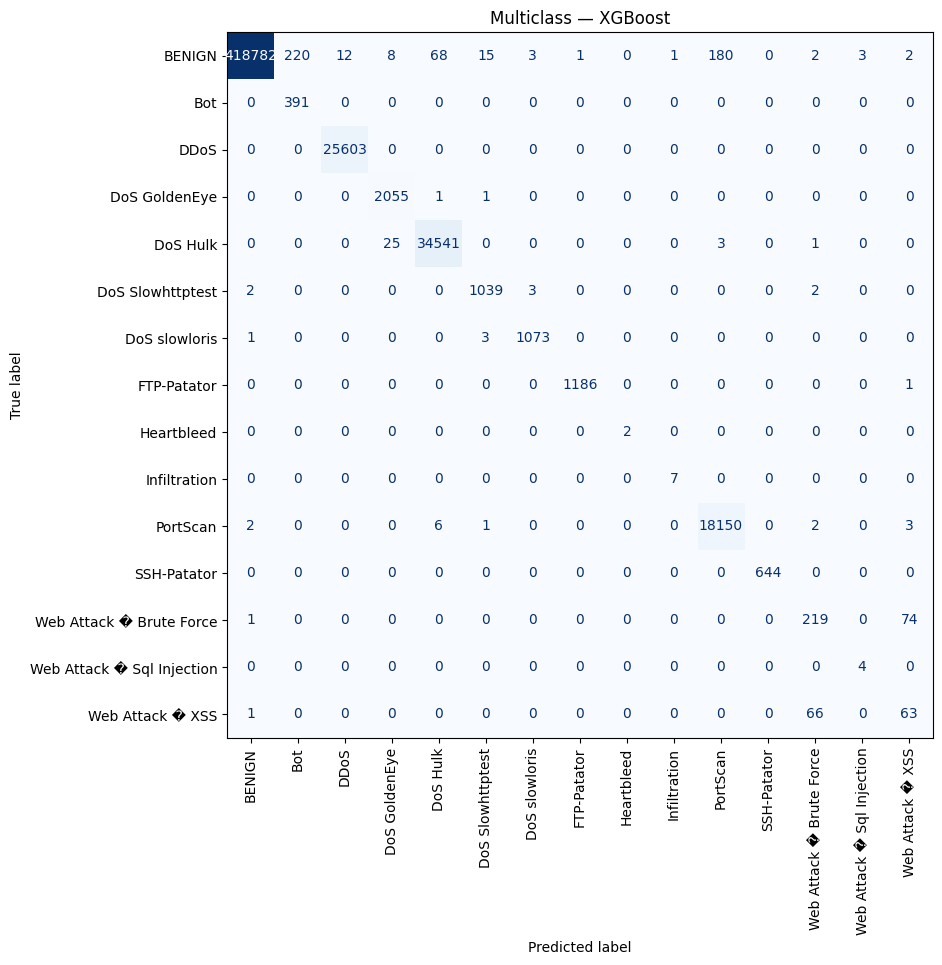


 LightGBM — Multiclass classification report


,precision,recall,f1-score,support
BENIGN,0.980195,0.451022,0.617781,419297.00000
Bot,0.038346,0.846547,0.073368,391.00000
DDoS,0.251941,0.357341,0.295525,25603.00000
DoS GoldenEye,0.002478,0.027224,0.004542,2057.00000
DoS Hulk,0.535048,0.892045,0.668894,34570.00000
DoS Slowhttptest,0.242086,0.745698,0.365511,1046.00000
DoS slowloris,0.046359,0.889508,0.088124,1077.00000
FTP-Patator,0.098482,0.973041,0.178862,1187.00000
Heartbleed,0.000733,1.000000,0.001465,2.00000
Infiltration,0.000145,0.714286,0.000289,7.00000


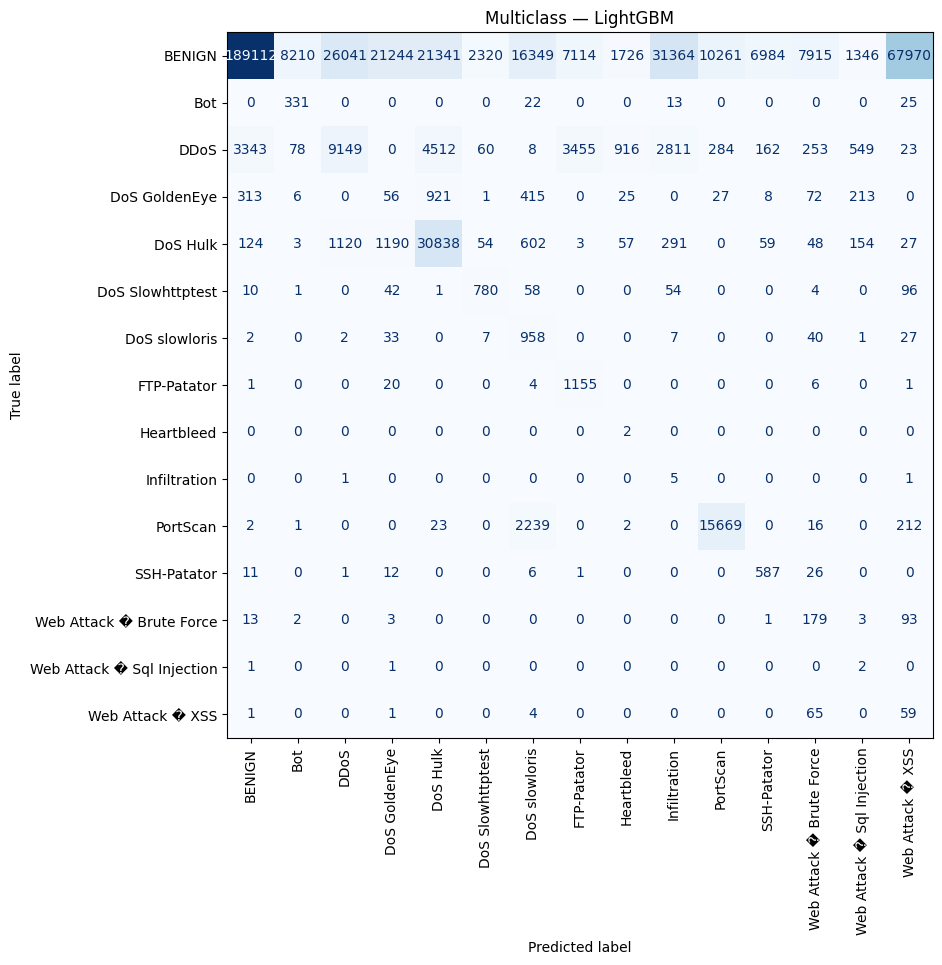


 CatBoost — Multiclass classification report


,precision,recall,f1-score,support
BENIGN,0.999961,0.986480,0.993175,419297.000000
Bot,0.095250,1.000000,0.173932,391.000000
DDoS,0.996457,0.999570,0.998011,25603.000000
DoS GoldenEye,0.897335,0.998542,0.945237,2057.000000
DoS Hulk,0.980431,0.998525,0.989395,34570.000000
DoS Slowhttptest,0.853279,0.995220,0.918800,1046.000000
DoS slowloris,0.977982,0.989786,0.983849,1077.000000
FTP-Patator,0.974444,0.995788,0.985000,1187.000000
Heartbleed,0.166667,1.000000,0.285714,2.000000
Infiltration,0.074074,0.857143,0.136364,7.000000


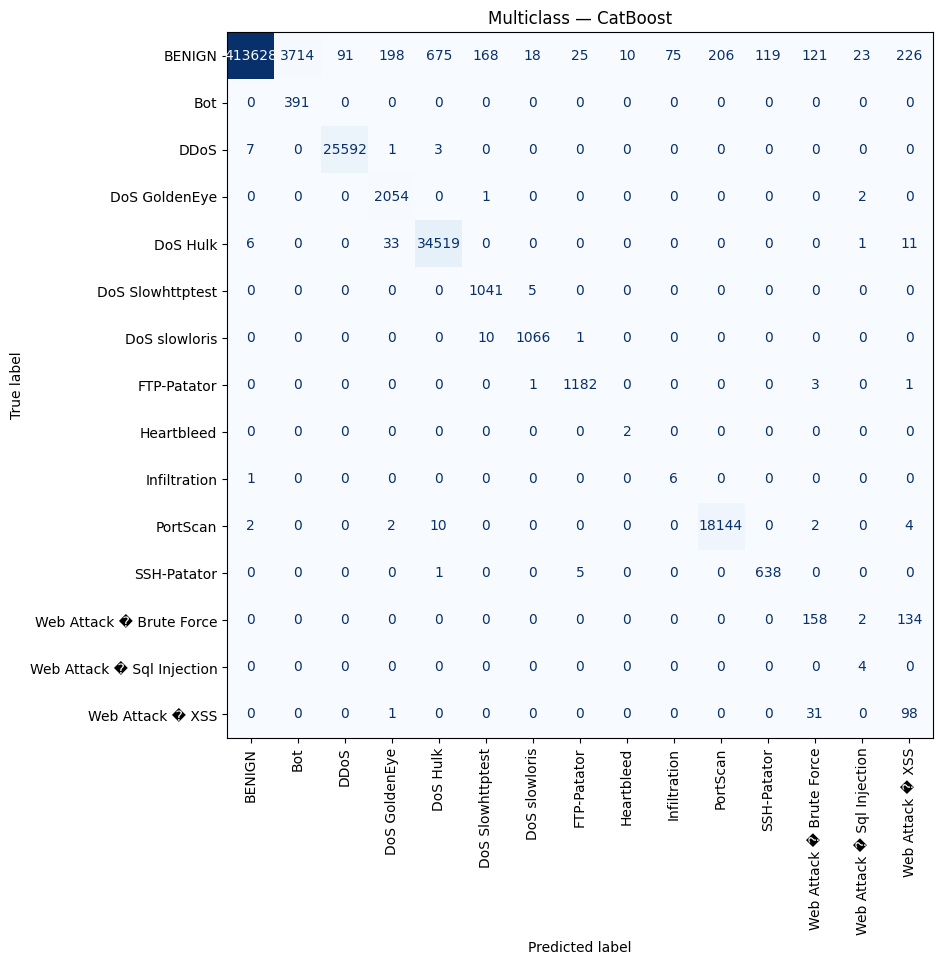

In [ ]:
for model_name, report_df in multiclass_results["reports"].items():
    print("\n", model_name, "— Multiclass classification report")
    display(report_df)
    safe_name = re.sub(r"[^a-z0-9]+", "_", model_name.lower()).strip("_")
    report_df.to_csv(OUTPUT_DIR / f"multiclass_{safe_name}_classification_report.csv")

    cm = multiclass_results["confusion_matrices"][model_name]
    cm_df = pd.DataFrame(
        cm,
        index=multiclass_results["label_names"],
        columns=multiclass_results["label_names"]
    )
    cm_df.to_csv(OUTPUT_DIR / f"multiclass_{safe_name}_confusion_matrix.csv")

    fig_width = max(7, len(multiclass_results["label_names"]) * 0.65)
    fig, ax = plt.subplots(figsize=(fig_width, fig_width))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=multiclass_results["label_names"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90, values_format="d")
    ax.set_title(f"Multiclass — {model_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"multiclass_{safe_name}_confusion_matrix.png", dpi=160)
    plt.show()

### Cell 21 -  Compare all experiments

,experiment,model,train_samples,test_samples,n_features,training_time_seconds,inference_time_seconds,accuracy,precision_macro,recall_macro,f1_macro,fpr_macro_ovr
0,Binary,XGBoost,2017889,504473,70,53.406903,0.770659,0.999047,0.997344,0.999272,0.998305,0.000728
1,Binary,LightGBM,2017889,504473,70,40.156578,1.792130,0.998989,0.997129,0.999284,0.998203,0.000716
2,Binary,CatBoost,2017889,504473,70,70.682187,0.389917,0.998858,0.996783,0.999168,0.997971,0.000832
3,Binary,Random Forest,2017889,504473,70,442.097942,2.188544,0.998608,0.997683,0.997357,0.997520,0.002643
4,Multiclass,XGBoost,2017889,504473,70,419.978697,6.776776,0.998585,0.881546,0.947630,0.907701,0.000101
5,Multiclass,Random Forest,2017889,504473,70,431.194921,3.218450,0.998301,0.937910,0.874039,0.898037,0.000379
6,Multiclass,CatBoost,2017889,504473,70,1591.152485,0.598951,0.988206,0.645386,0.940126,0.691978,0.000806
7,Multiclass,LightGBM,2017889,504473,70,231.806777,13.496197,0.493350,0.192712,0.682236,0.212182,0.036794


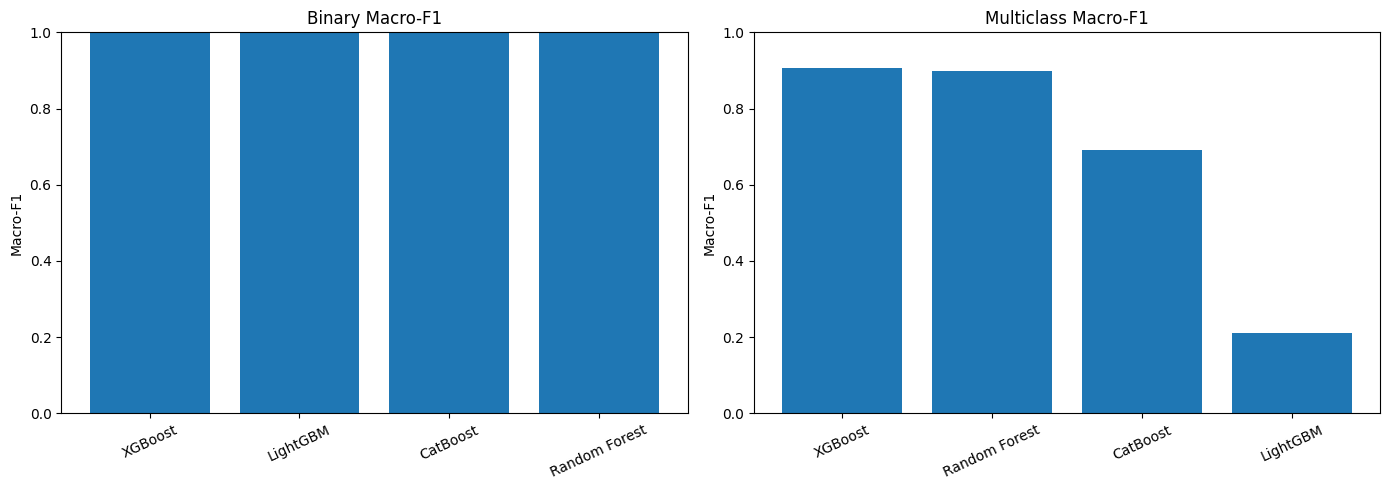

In [ ]:
all_results = pd.concat(
    [binary_results["results"], multiclass_results["results"]],
    ignore_index=True
)
display(all_results.sort_values(["experiment", "f1_macro"], ascending=[True, False]))
all_results.to_csv(OUTPUT_DIR / "all_experiments_model_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, exp_name in zip(axes, ["Binary", "Multiclass"]):
    subset = all_results[all_results["experiment"] == exp_name].sort_values("f1_macro", ascending=False)
    ax.bar(subset["model"], subset["f1_macro"])
    ax.set_title(f"{exp_name} Macro-F1")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("Macro-F1")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "binary_vs_multiclass_macro_f1.png", dpi=160)
plt.show()

### Cell 22 - Feature importance

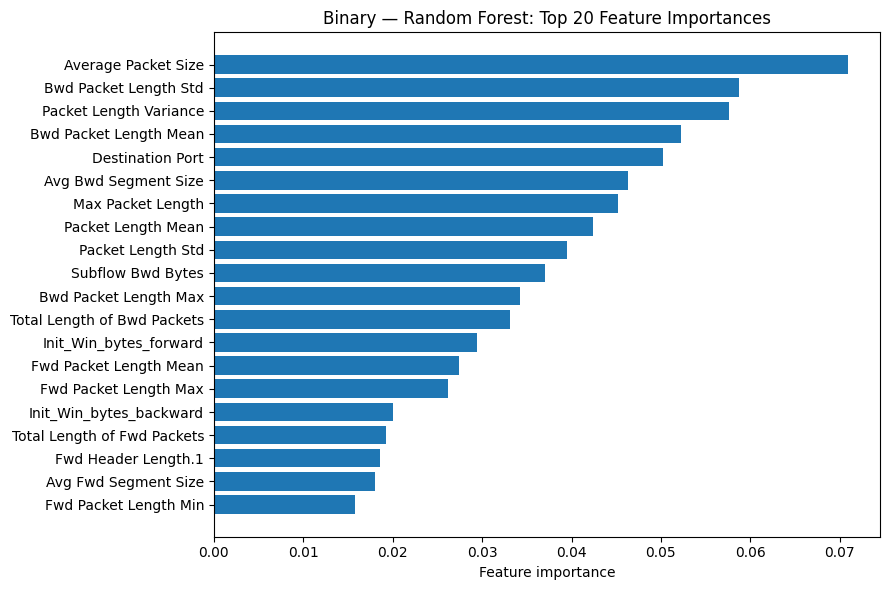

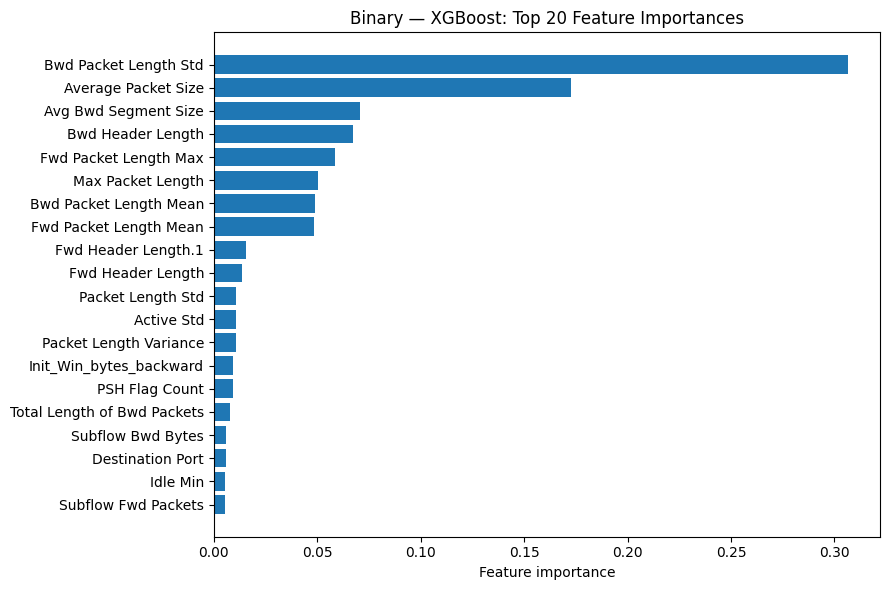

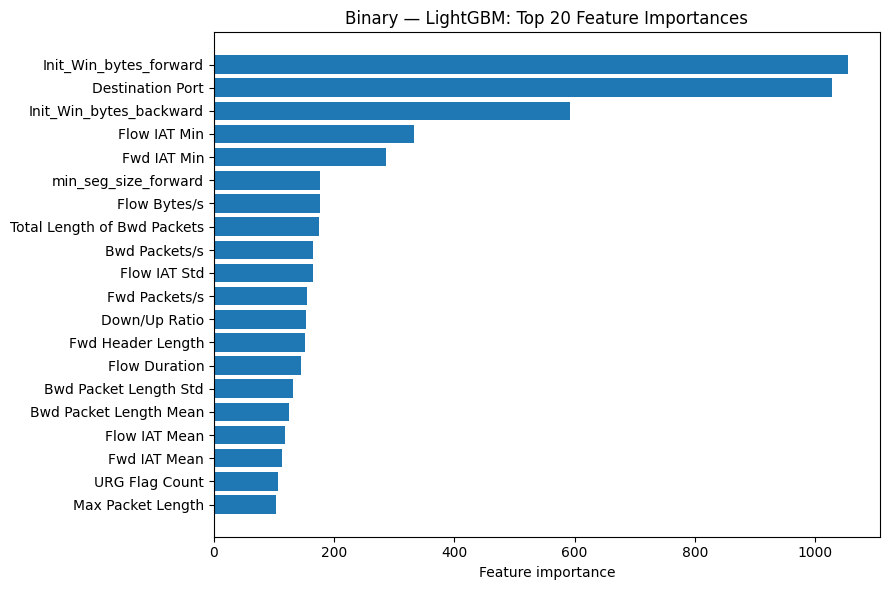

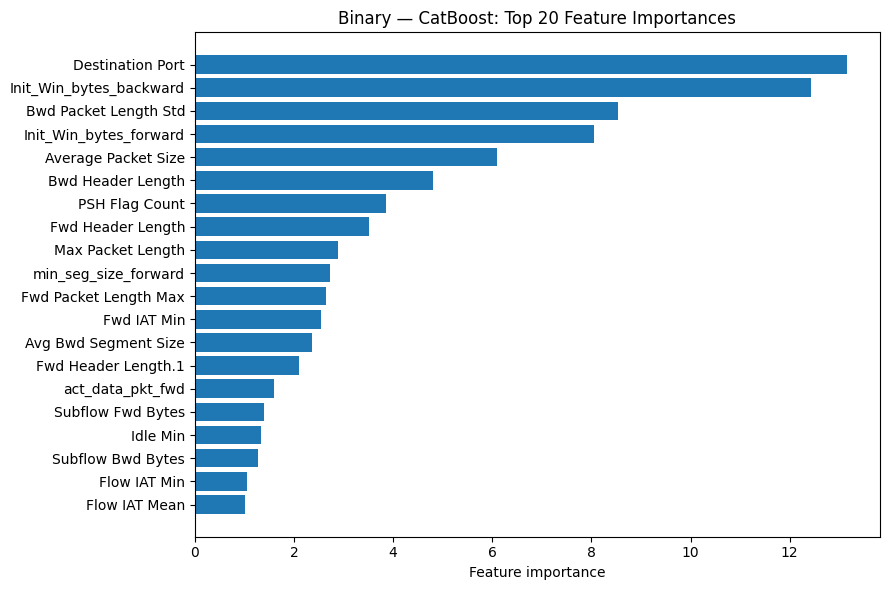

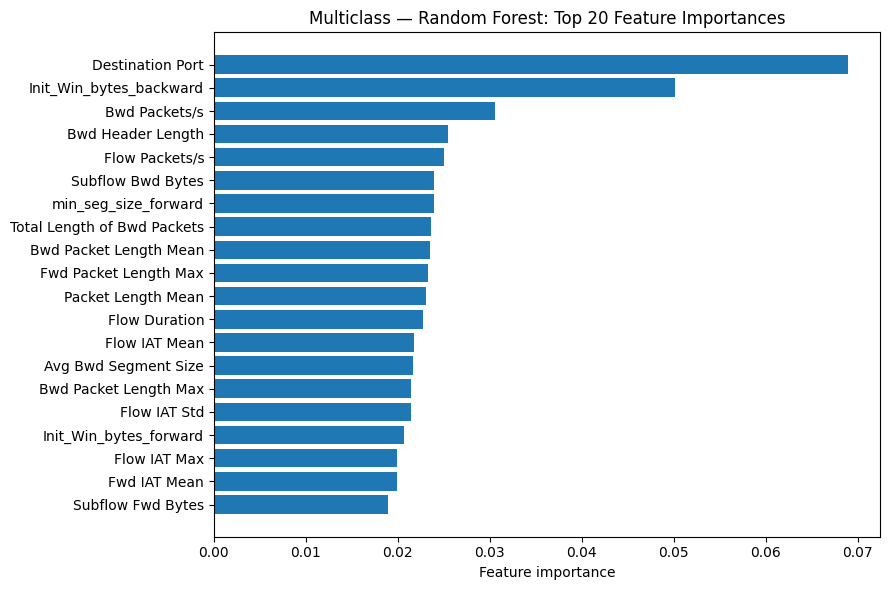

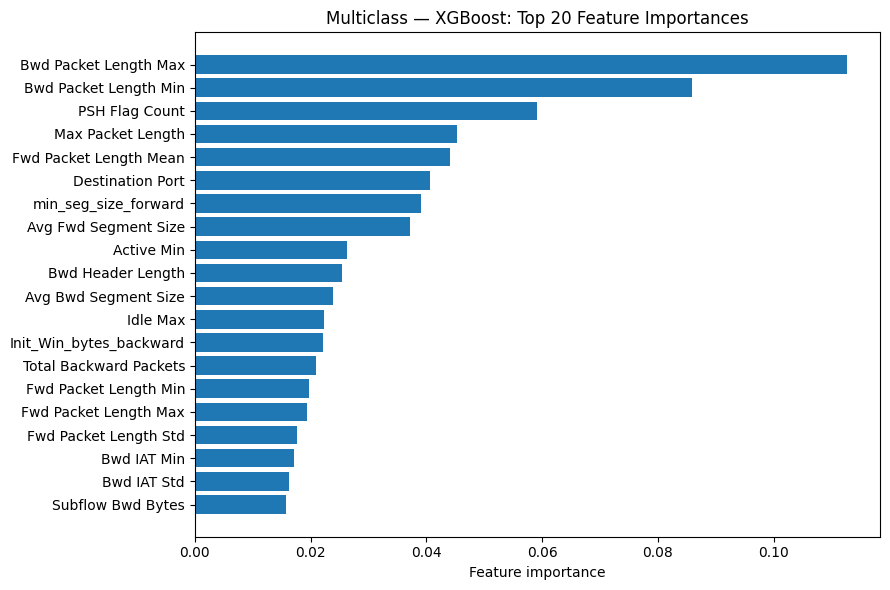

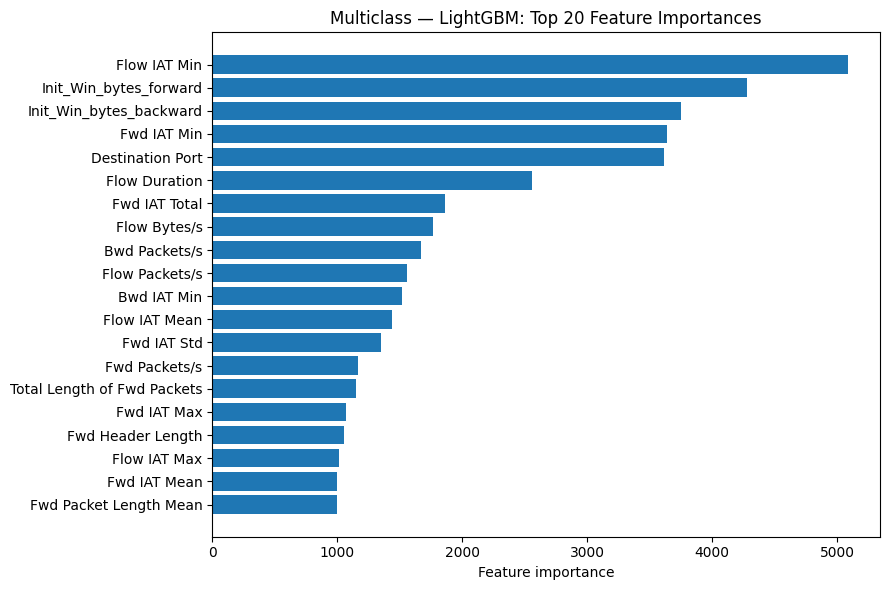

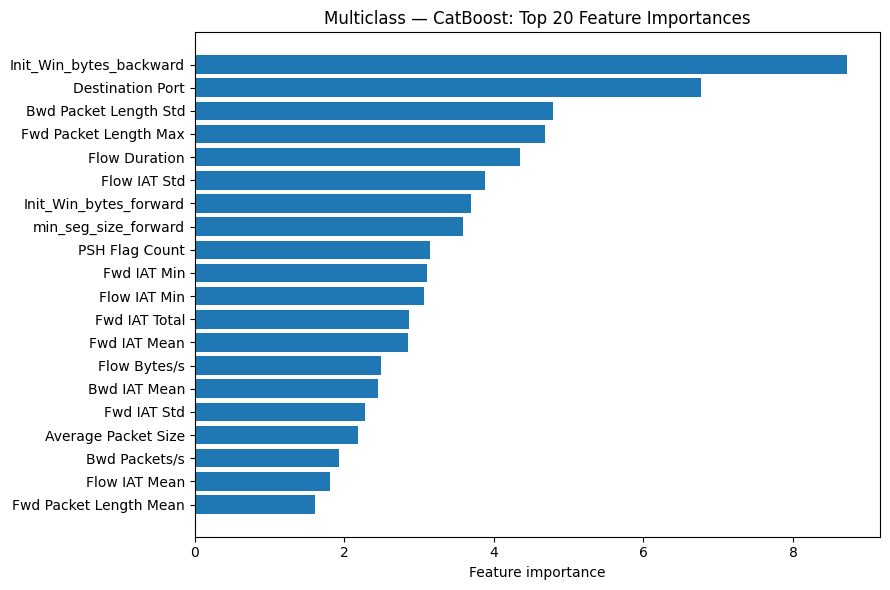

In [ ]:
importance_all = pd.concat(
    [
        binary_results["feature_importance"],
        multiclass_results["feature_importance"]
    ],
    ignore_index=True
)

if not importance_all.empty:
    importance_all.to_csv(OUTPUT_DIR / "feature_importance_all_models.csv", index=False)

    for exp_name in ["Binary", "Multiclass"]:
        subset = importance_all[importance_all["experiment"] == exp_name]
        if subset.empty:
            continue
        # Plot top 20 features separately for each model.
        for model_name in subset["model"].unique():
            top = subset[subset["model"] == model_name].nlargest(20, "importance")
            plt.figure(figsize=(9, 6))
            plt.barh(top["feature"][::-1], top["importance"][::-1])
            plt.title(f"{exp_name} — {model_name}: Top 20 Feature Importances")
            plt.xlabel("Feature importance")
            plt.tight_layout()
            safe_name = re.sub(r"[^a-z0-9]+", "_", model_name.lower()).strip("_")
            plt.savefig(OUTPUT_DIR / f"{exp_name.lower()}_{safe_name}_top_features.png", dpi=160)
            plt.show()
else:
    print("Feature importance is not available from the fitted estimators.")

### Cell 23 - Save the best models and encoders

In [ ]:
# Best model is selected by macro-F1 within each experiment.
best_binary_name = binary_results["results"].iloc[0]["model"]
best_multiclass_name = multiclass_results["results"].iloc[0]["model"]

best_binary_model = binary_results["models"][best_binary_name]
best_multiclass_model = multiclass_results["models"][best_multiclass_name]

joblib.dump(best_binary_model, OUTPUT_DIR / "best_binary_intrusion_model.joblib")
joblib.dump(best_multiclass_model, OUTPUT_DIR / "best_multiclass_intrusion_model.joblib")
joblib.dump(binary_results["label_encoder"], OUTPUT_DIR / "binary_label_encoder.joblib")
joblib.dump(multiclass_results["label_encoder"], OUTPUT_DIR / "multiclass_label_encoder.joblib")

print("Best binary model:", best_binary_name)
print("Best multiclass model:", best_multiclass_name)

Best binary model: XGBoost
Best multiclass model: XGBoost


### Cell 24 -  Create prediction samples and error analysis for best models

In [ ]:
def export_error_analysis(result_bundle, best_model_name, prefix):
    model = result_bundle["models"][best_model_name]
    X_test_local = result_bundle["X_test"]
    y_test_local = result_bundle["y_test"]
    encoder = result_bundle["label_encoder"]
    labels = result_bundle["label_names"]

    pred = model.predict(X_test_local)
    pred = np.asarray(pred).reshape(-1).astype(int)

    out = pd.DataFrame({
        "actual_label": encoder.inverse_transform(np.asarray(y_test_local, dtype=int)),
        "predicted_label": encoder.inverse_transform(pred),
        "correct": np.asarray(y_test_local) == pred
    })

    if hasattr(model, "predict_proba"):
        try:
            probs = model.predict_proba(X_test_local)
            out["prediction_confidence"] = np.max(probs, axis=1)
        except Exception:
            pass

    out.to_csv(OUTPUT_DIR / f"{prefix}_best_model_test_predictions.csv", index=False)
    out.loc[~out["correct"]].head(1000).to_csv(
        OUTPUT_DIR / f"{prefix}_best_model_misclassified_examples.csv", index=False
    )

    error_summary = (
        out.assign(error=~out["correct"])
           .groupby("actual_label")["error"]
           .agg(["sum", "count", "mean"])
           .reset_index()
           .rename(columns={"sum": "errors", "count": "samples", "mean": "error_rate"})
    )
    error_summary.to_csv(OUTPUT_DIR / f"{prefix}_best_model_class_error_analysis.csv", index=False)
    return out, error_summary

binary_predictions, binary_error_summary = export_error_analysis(
    binary_results, best_binary_name, "binary"
)
multiclass_predictions, multiclass_error_summary = export_error_analysis(
    multiclass_results, best_multiclass_name, "multiclass"
)

display(binary_error_summary)
display(multiclass_error_summary)

,actual_label,errors,samples,error_rate
0,ATTACK,33,85176,0.000387
1,BENIGN,448,419297,0.001068


,actual_label,errors,samples,error_rate
0,BENIGN,515,419297,0.001228
1,Bot,0,391,0.000000
2,DDoS,0,25603,0.000000
3,DoS GoldenEye,2,2057,0.000972
4,DoS Hulk,29,34570,0.000839
5,DoS Slowhttptest,7,1046,0.006692
6,DoS slowloris,4,1077,0.003714
7,FTP-Patator,1,1187,0.000842
8,Heartbleed,0,2,0.000000
9,Infiltration,0,7,0.000000


### Cell 25 -  Save experiment summary and data audit

In [ ]:
summary = {
    "project": "Project 12 - ML-Based Network Intrusion Detection",
    "dataset": "CICIDS2017",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_csv_files": file_load_log,
    "raw_combined_rows_before_cleaning": int(sum(x["rows"] for x in file_load_log)),
    "rows_after_cleaning_and_exact_deduplication": int(len(df)),
    "exact_duplicate_rows_removed": int(duplicates_removed),
    "feature_count": int(X_raw.shape[1]),
    "feature_columns": list(X_raw.columns),
    "binary_class_distribution": {str(k): int(v) for k, v in y_binary.value_counts().items()},
    "multiclass_class_distribution": {str(k): int(v) for k, v in y_multiclass.value_counts().items()},
    "binary_best_model_by_macro_f1": str(best_binary_name),
    "multiclass_best_model_by_macro_f1": str(best_multiclass_name),
    "binary_results": binary_results["results"].to_dict(orient="records"),
    "multiclass_results": multiclass_results["results"].to_dict(orient="records"),
    "test_size": TEST_SIZE,
    "random_seed": SEED,
    "max_training_rows": MAX_TRAINING_ROWS,
    "split_note": "Stratified random holdout; not a temporal or cross-dataset generalization test.",
    "feature_exclusion_note": "Flow ID, Source IP, Destination IP, Timestamp, label, and source filename excluded from model features."
}

with open(OUTPUT_DIR / "project12_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("Summary saved.")

Summary saved.


### Cell 26 -  Verify generated files

In [ ]:
output_files = sorted(OUTPUT_DIR.glob("*"))
file_table = pd.DataFrame([
    {
        "file": p.name,
        "size_mb": round(p.stat().st_size / (1024**2), 3),
        "type": "directory" if p.is_dir() else "file"
    }
    for p in output_files
])
display(file_table)
file_table.to_csv(OUTPUT_DIR / "generated_files_manifest.csv", index=False)

print("Output directory:", OUTPUT_DIR)
print("Total entries:", len(output_files))

,file,size_mb,type
0,all_experiments_model_comparison.csv,0.001,file
1,best_binary_intrusion_model.joblib,1.165,file
2,best_multiclass_intrusion_model.joblib,10.256,file
3,binary_best_model_class_error_analysis.csv,0.000,file
4,binary_best_model_misclassified_examples.csv,0.014,file
5,binary_best_model_test_predictions.csv,14.124,file
6,binary_catboost_classification_report.csv,0.000,file
7,binary_catboost_confusion_matrix.csv,0.000,file
8,binary_catboost_confusion_matrix.png,0.026,file
9,binary_catboost_top_features.png,0.099,file


Output directory: /content/drive/MyDrive/Colab Notebooks/Projects House/Project-12/Project12_Outputs
Total entries: 53


## 27. Research interpretation and limitations

Before using the results in a thesis or paper, discuss the following:

1. **Class imbalance:** CICIDS2017 contains highly imbalanced attack categories. Report macro-F1, per-class recall, and confusion matrices rather than accuracy alone.
2. **Duplicate records:** Exact duplicate rows were removed before splitting. This does not guarantee removal of near-duplicates or capture-level dependence.
3. **Potential split leakage:** A stratified random split may place related flows from the same capture period in both train and test. Treat results as a random-holdout baseline.
4. **Feature selection:** Identifier-like columns (`Flow ID`, source/destination IP, timestamp) were excluded. Document any further exclusions and justify them.
5. **Multiclass label coverage:** The notebook uses all labels present in the loaded CSV files. Verify that all expected CICIDS2017 attack categories are represented.
6. **Reproducibility:** Record the exact source files, library versions, runtime type, and configuration used for final thesis experiments.
7. **Generalization:** Add a separate time-aware, day-wise, or cross-dataset evaluation before making strong claims about unseen network environments.

**Do not report a result as full-dataset training if `MAX_TRAINING_ROWS` was changed from `None`.**

### Cell 28 - Download results as a ZIP archive

In [ ]:
import shutil

zip_base = "/content/Project12_Outputs"
zip_path = shutil.make_archive(zip_base, "zip", root_dir=OUTPUT_DIR)

print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)

ZIP created: /content/Project12_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 29. Final checklist

- [ ] All intended CICIDS2017 CSV files were loaded.
- [ ] Source-file audit was reviewed.
- [ ] Label distribution and rare classes were checked.
- [ ] Exact duplicates and missing/infinite values were handled.
- [ ] Identifier-like columns were excluded from model features.
- [ ] Binary experiment completed for all four models.
- [ ] Multiclass experiment completed for all four models.
- [ ] Macro-F1, per-class metrics, FPR, and confusion matrices were reviewed.
- [ ] Best models and encoders were saved.
- [ ] `project12_summary.json` and generated files manifest were reviewed.
- [ ] Random-holdout limitations are documented before thesis reporting.